Example Nemseer following tutorial:
https://nemseer.readthedocs.io/en/latest/examples/visualising_p5min_demand_forecasts.html

In [1]:
!uv pip install "pandas<3.0"

In [2]:
from pathlib import Path

import nemosis
from nemseer import compile_data, generate_runtimes
import nemseer

import plotly.graph_objects as go

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import xarray as xr

import hvplot.pandas
hvplot.extension("plotly")

# for some advanced colour manipulation
from matplotlib.colors import to_hex
import numpy as np

import plotly.io as pio
import plotly.express as px

import pandas as pd

import math

print("pandas:", pd.__version__)
print("nemseer:", getattr(nemseer, "__version__", "unknown"))

pandas: 2.3.3
nemseer: 1.0.7


In [3]:
start, end = "2022/07/14 16:55:00", "2022/07/14 19:00:00"

In [4]:
p5_run_start, p5_run_end = generate_runtimes(start, end, "P5MIN")

p5_data = compile_data(
    p5_run_start,
    p5_run_end,
    start,
    end,
    "P5MIN",
    "REGIONSOLUTION",
    raw_cache="nemseer_cache/",
    data_format="df",
)

INFO: Query raw data already downloaded to nemseer_cache


In [5]:
df = p5_data["REGIONSOLUTION"]
df.head()

,RUN_DATETIME,INTERVENTION,INTERVAL_DATETIME,REGIONID,RRP,ROP,EXCESSGENERATION,RAISE6SECRRP,RAISE6SECROP,RAISE60SECRRP,...,SEMISCHEDULE_COMPLIANCEMW,SS_SOLAR_UIGF,SS_WIND_UIGF,SS_SOLAR_CLEAREDMW,SS_WIND_CLEAREDMW,SS_SOLAR_COMPLIANCEMW,SS_WIND_COMPLIANCEMW,WDR_INITIALMW,WDR_AVAILABLE,WDR_DISPATCHED
0,2022-07-14 16:00:00,0,2022-07-14 16:55:00,NSW1,672.700562,672.70054,0.0,30.00,30.00,19.950001,...,94.047997,611.257996,279.643005,611.257996,279.643005,0.0,94.047997,0,0,0
1,2022-07-14 16:00:00,0,2022-07-14 16:55:00,QLD1,150.729996,150.73000,0.0,30.00,30.00,19.950001,...,0.000000,735.242981,182.302994,735.242981,182.302994,0.0,0.000000,0,0,0
2,2022-07-14 16:00:00,0,2022-07-14 16:55:00,SA1,710.390015,710.39004,0.0,30.00,30.00,19.950001,...,0.000000,157.253693,34.951000,157.253693,34.951000,0.0,0.000000,0,0,0
3,2022-07-14 16:00:00,0,2022-07-14 16:55:00,TAS1,588.570007,588.57000,0.0,14.23,14.23,4.130000,...,0.000000,0.000000,49.021000,0.000000,49.021000,0.0,0.000000,0,0,0
4,2022-07-14 16:00:00,0,2022-07-14 16:55:00,VIC1,776.000000,776.00000,0.0,30.00,30.00,19.950001,...,0.000000,150.453995,78.536003,150.453995,78.536003,0.0,0.000000,0,0,0


In [6]:
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)

(1560, 104)
['RUN_DATETIME', 'INTERVENTION', 'INTERVAL_DATETIME', 'REGIONID', 'RRP', 'ROP', 'EXCESSGENERATION', 'RAISE6SECRRP', 'RAISE6SECROP', 'RAISE60SECRRP', 'RAISE60SECROP', 'RAISE5MINRRP', 'RAISE5MINROP', 'RAISEREGRRP', 'RAISEREGROP', 'LOWER6SECRRP', 'LOWER6SECROP', 'LOWER60SECRRP', 'LOWER60SECROP', 'LOWER5MINRRP', 'LOWER5MINROP', 'LOWERREGRRP', 'LOWERREGROP', 'TOTALDEMAND', 'AVAILABLEGENERATION', 'AVAILABLELOAD', 'DEMANDFORECAST', 'DISPATCHABLEGENERATION', 'DISPATCHABLELOAD', 'NETINTERCHANGE', 'LOWER5MINDISPATCH', 'LOWER5MINIMPORT', 'LOWER5MINLOCALDISPATCH', 'LOWER5MINLOCALREQ', 'LOWER5MINREQ', 'LOWER60SECDISPATCH', 'LOWER60SECIMPORT', 'LOWER60SECLOCALDISPATCH', 'LOWER60SECLOCALREQ', 'LOWER60SECREQ', 'LOWER6SECDISPATCH', 'LOWER6SECIMPORT', 'LOWER6SECLOCALDISPATCH', 'LOWER6SECLOCALREQ', 'LOWER6SECREQ', 'RAISE5MINDISPATCH', 'RAISE5MINIMPORT', 'RAISE5MINLOCALDISPATCH', 'RAISE5MINLOCALREQ', 'RAISE5MINREQ', 'RAISE60SECDISPATCH', 'RAISE60SECIMPORT', 'RAISE60SECLOCALDISPATCH', 'RAISE60S

In [7]:
mask = (
    (df["REGIONID"] == "NSW1") & 
    (df["INTERVAL_DATETIME"] >= start) &
    (df["INTERVAL_DATETIME"] <= end)
)
p5_demand_forecasts = df.loc[mask, "TOTALDEMAND"]
p5_demand_forecasts.head()

0     10379.709961
5     10437.080078
6     10477.990234
15    10423.160156
16    10464.509766
Name: TOTALDEMAND, dtype: float32

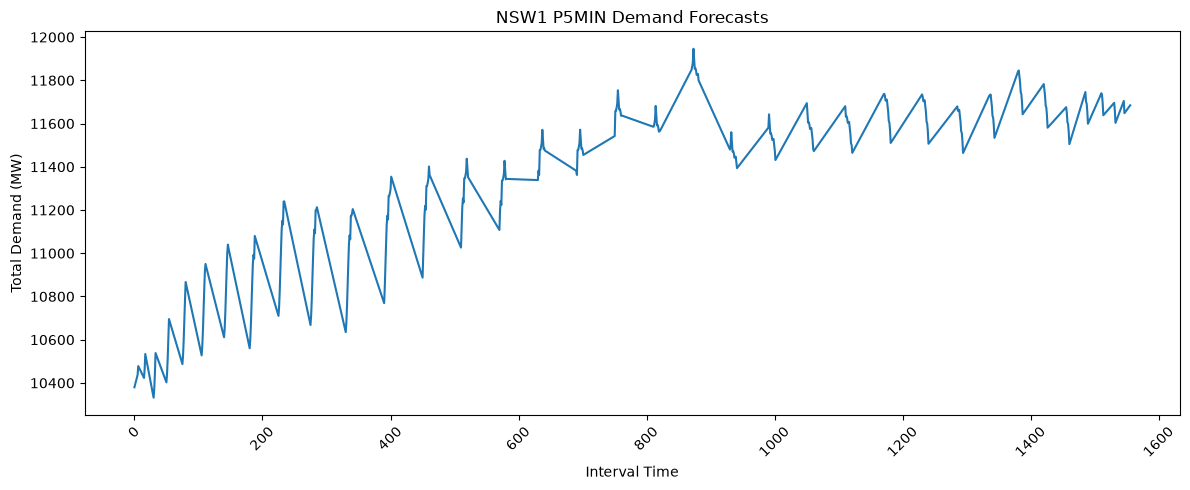

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(p5_demand_forecasts.index, p5_demand_forecasts.values)
plt.xlabel("Interval Time")
plt.ylabel("Total Demand (MW)")
plt.title("NSW1 P5MIN Demand Forecasts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# Filter to NSW1 within mask
sub = df.loc[mask, ["RUN_DATETIME", "INTERVAL_DATETIME", "TOTALDEMAND"]]

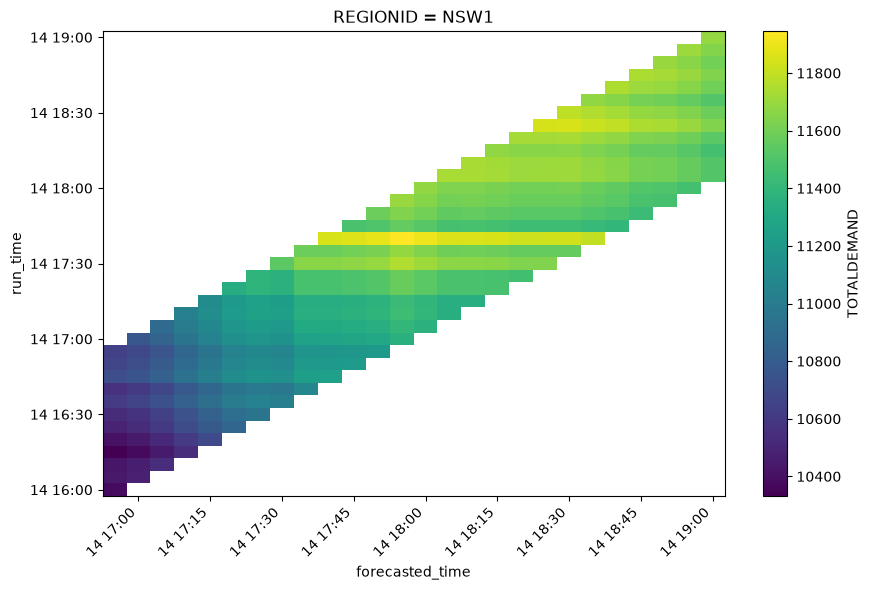

In [10]:
# Pivot into a 2D grid: rows = RUN_DATETIME, columns = INTERVAL_DATETIME
pivot = sub.pivot_table(
    index="RUN_DATETIME",
    columns="INTERVAL_DATETIME",
    values="TOTALDEMAND"
)

fig, ax = plt.subplots(figsize=(9, 6))

mesh = ax.pcolormesh(
    pivot.columns,   # forecasted_time
    pivot.index,     # run_time
    pivot.values,
    cmap="viridis",
    shading="auto",
)

fig.colorbar(mesh, ax=ax, label="TOTALDEMAND")
ax.set_xlabel("forecasted_time")
ax.set_ylabel("run_time")
ax.set_title("REGIONID = NSW1")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %H:%M"))
ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %H:%M"))
fig.autofmt_xdate(rotation=45)

plt.tight_layout()
plt.show()

In [12]:
nemosis_cache = Path("nemosis_cache/")
if not nemosis_cache.exists():
    nemosis_cache.mkdir()

# get demand data for NSW
nsw_demand = nemosis.dynamic_data_compiler(
  start, end, "DISPATCHREGIONSUM", nemosis_cache,
  filter_cols=["REGIONID", "INTERVENTION"],
  filter_values=(["NSW1"],[0])
)
nsw_demand = nsw_demand.set_index('SETTLEMENTDATE').sort_index()

INFO: Compiling data for table DISPATCHREGIONSUM
INFO: Returning DISPATCHREGIONSUM.


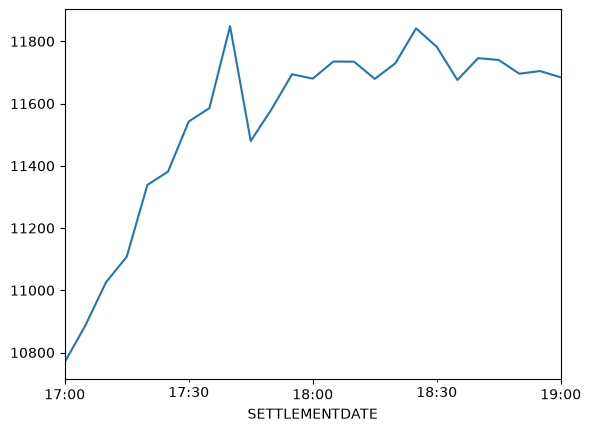

In [13]:
nsw_demand["TOTALDEMAND"].plot();

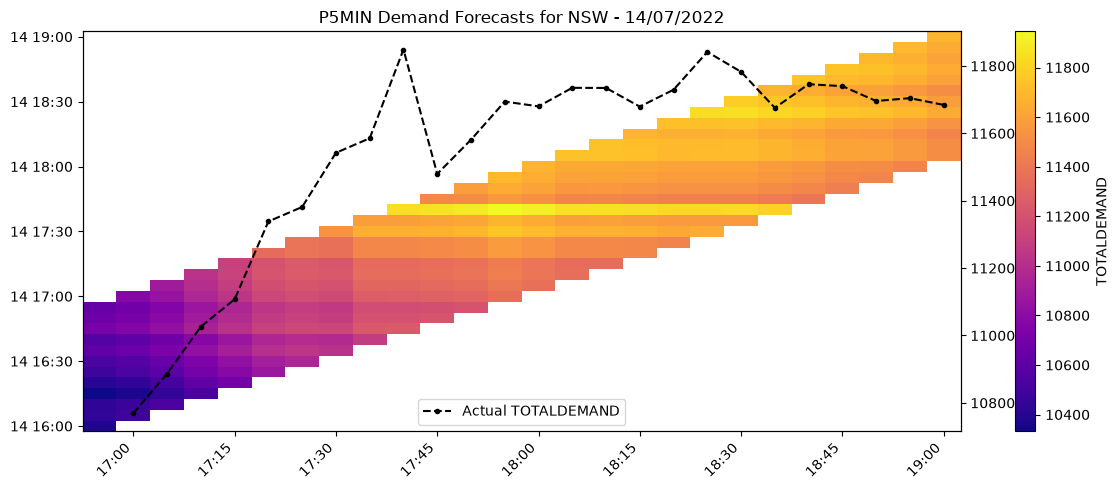

In [14]:
# Rebuild the 2D grid (run_time x forecasted_time)
pivot = sub.pivot_table(index="RUN_DATETIME", columns="INTERVAL_DATETIME", values="TOTALDEMAND")

fig, ax = plt.subplots(1, 1, figsize=(12, 5))

mesh = ax.pcolormesh(
    pivot.columns, pivot.index, pivot.values,
    cmap="plasma", shading="auto"
)
fig.colorbar(mesh, ax=ax, label="TOTALDEMAND")

ax_demand = ax.twinx()
ax_demand.plot(
    nsw_demand.index, nsw_demand["TOTALDEMAND"],
    ls="--", marker=".", color="black", label="Actual TOTALDEMAND"
)
ax_demand.legend(loc="lower center")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.autofmt_xdate(rotation=45)
ax.set_title("P5MIN Demand Forecasts for NSW - 14/07/2022")

plt.tight_layout()
plt.show()

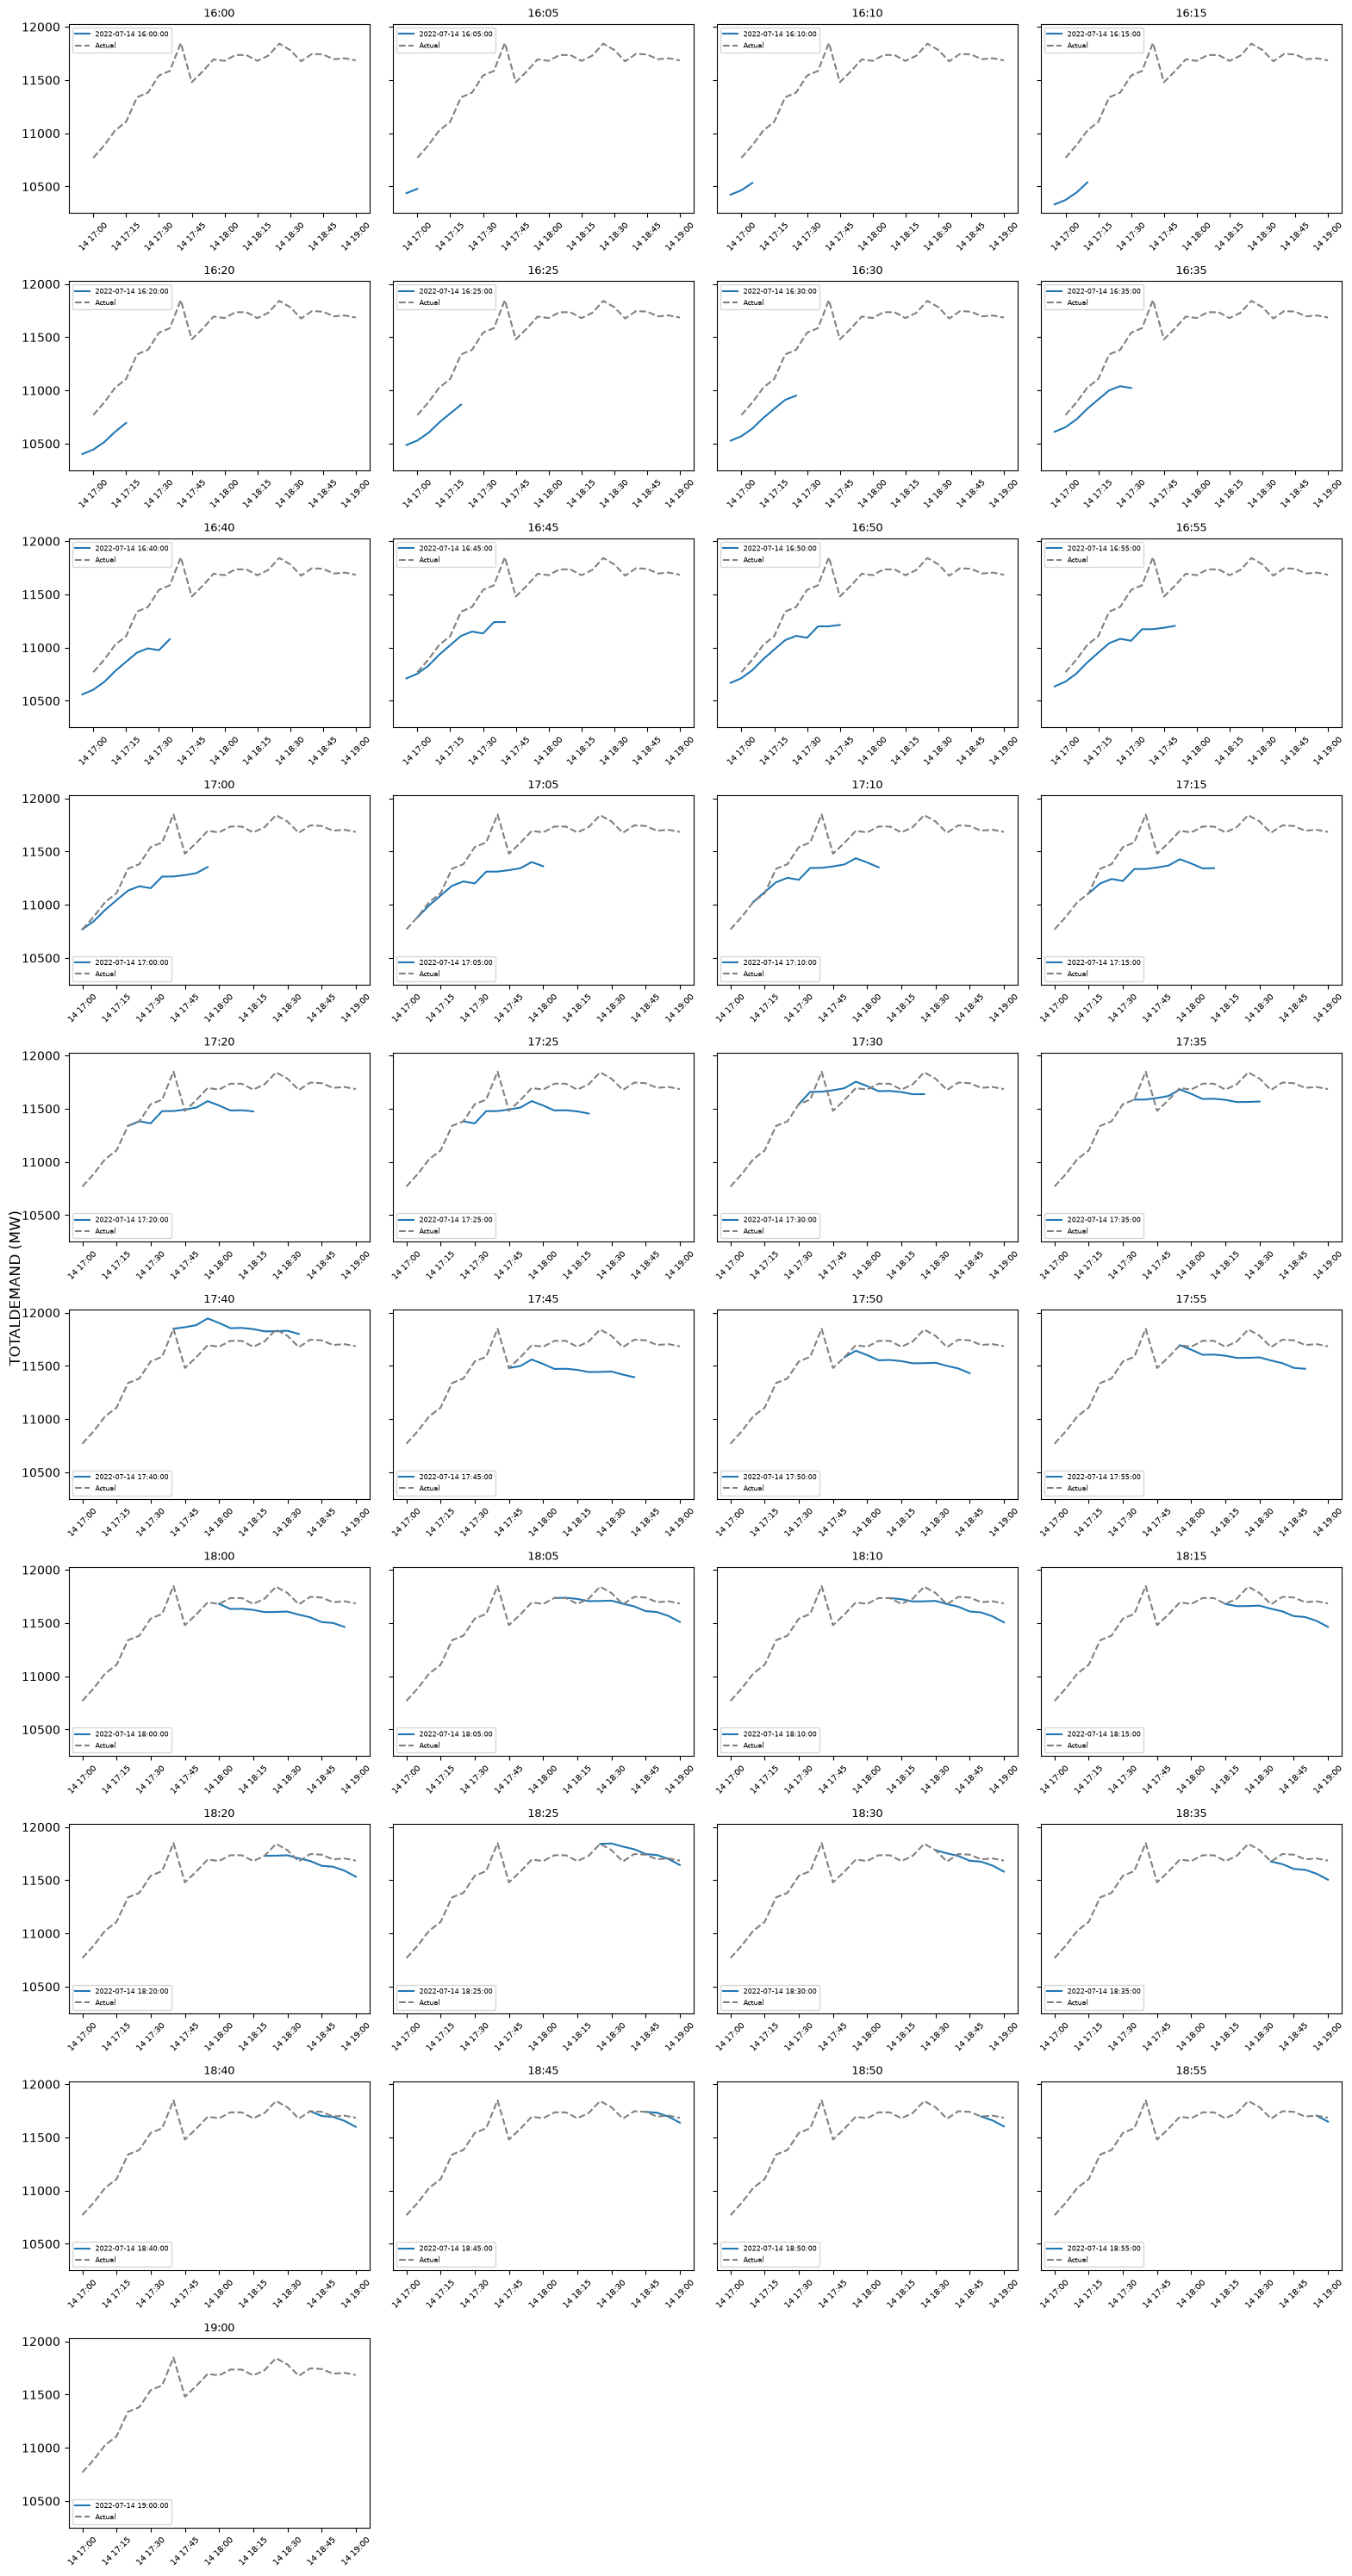

In [15]:
run_times = sorted(sub["RUN_DATETIME"].unique())
n = len(run_times)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), sharex=False, sharey=True)
axes = axes.flatten()

for ax, rt in zip(axes, run_times):
    run_data = sub[sub["RUN_DATETIME"] == rt].sort_values("INTERVAL_DATETIME")
    ax.plot(run_data["INTERVAL_DATETIME"], run_data["TOTALDEMAND"], label=str(rt))
    ax.plot(nsw_demand.index, nsw_demand["TOTALDEMAND"], label="Actual", ls="--", color="gray")
    ax.set_title(pd.Timestamp(rt).strftime("%H:%M"), fontsize=9)
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.legend(fontsize=6)

# Hide any unused axes if run_times doesn't fill the grid evenly
for ax in axes[n:]:
    ax.axis("off")

fig.supylabel("TOTALDEMAND (MW)")
plt.tight_layout()
plt.show()

In [16]:
# Generate interactive heatmap
hmap = sub.hvplot.heatmap(
    x="INTERVAL_DATETIME", y="RUN_DATETIME", C="TOTALDEMAND", cmap="plasma",
    title="P5MIN Demand Forecasts for NSW - 14/07/2022"
)

# Create plotly.go.Figure from hvplot data structure
fig = go.Figure(hvplot.render(hmap, backend="plotly"))

# add actual demand as a line trace
line = go.Scatter(
    x=nsw_demand.index, y=nsw_demand["TOTALDEMAND"], yaxis="y2",
    line={"color": "black", "dash": "dash"}, name="Actual TOTALDEMAND",
)
fig.add_trace(line)

# update_layout defines the second y-axis and figure width and height
fig = fig.update_layout(
    xaxis=dict(domain=[0.1, 0.9]),
    yaxis2=dict(overlaying="y", title="Actual TOTALDEMAND (MW)", side="right"),
    height=300, width=700
)

fig